In [ ]:
!pip install ultralytics opencv-python

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving traff.jpeg to traff.jpeg



0: 448x640 1 person, 6 cars, 1 motorcycle, 1 bus, 96.1ms
Speed: 3.1ms preprocess, 96.1ms inference, 0.7ms postprocess per image at shape (1, 3, 448, 640)

Image: traff.jpeg
--------------------------
Person : 1
Bicycle : 0
Car : 6
Motorcycle : 1
Bus : 1
Truck : 0

Detection Result:


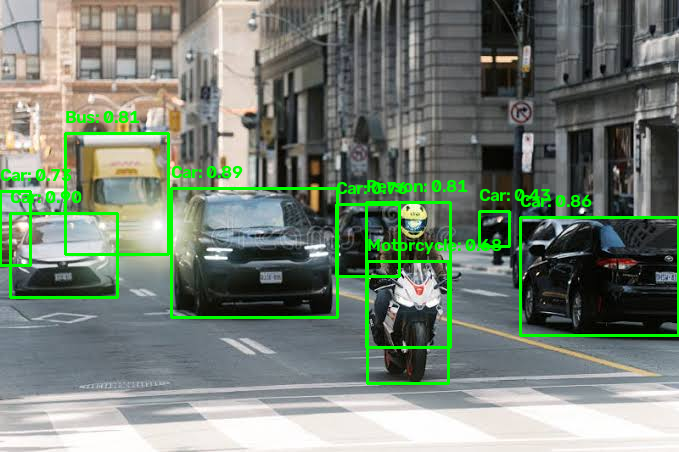


VisionPort Detection Completed!


In [ ]:

import cv2
from ultralytics import YOLO
from google.colab.patches import cv2_imshow
import os

model = YOLO("yolov8n.pt")

# Object classes
target_classes = {
    0: "Person",
    1: "Bicycle",
    2: "Car",
    3: "Motorcycle",
    5: "Bus",
    7: "Truck"
}

os.makedirs("output", exist_ok=True)

# Process uploaded images
for image_name in uploaded.keys():

    image = cv2.imread(image_name)

    if image is None:
        print("Cannot read image:", image_name)
        continue

    # Perform detection
    results = model(image, conf=0.40)

    counts = {
        name: 0 for name in target_classes.values()
    }

    for result in results:

        for box in result.boxes:

            class_id = int(box.cls[0])

            if class_id in target_classes:

                label = target_classes[class_id]
                confidence = float(box.conf[0])

                counts[label] += 1

                x1, y1, x2, y2 = map(
                    int, box.xyxy[0]
                )

                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                cv2.putText(
                    image,
                    f"{label}: {confidence:.2f}",
                    (x1, max(y1 - 10, 20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 255, 0),
                    2
                )

    # Display counts
    print("\nImage:", image_name)
    print("--------------------------")

    for name, count in counts.items():
        print(name, ":", count)

    # Save output
    output_path = "output/" + image_name
    cv2.imwrite(output_path, image)

    # Display detected image
    print("\nDetection Result:")
    cv2_imshow(image)

print("\nVisionPort Detection Completed!")
